# Giant Component and Phase Transition

Computer Science Dept, Ferdowsi University of Mashhad

In the previous page we counted edges, degrees and triangles in $G(n,p)$, and every answer was a
number: the expected degree is $(n-1)p$, the degree distribution is Poisson, the number of
triangles is roughly $\binom{n}{3}p^3$. This page asks a different kind of question — a
*geometric* one. When we raise $p$ from $0$ to $1$, at which point does the graph stop being a
dust of tiny components and grow one component that holds a positive fraction of all vertices?

The answer is a sharp change at $p = 1/n$, and the tool that explains it is the branching process.
This is the cleanest example in the course of a *threshold phenomenon*: a quantity that is $o(1)$
below a critical value and $\Theta(1)$ above it, with no gradual transition in between.

**Goals**

- Read the component of a vertex as a branching process, with mean offspring $c = np$.
- Derive the survival probability from the fixed-point equation $s = 1 - e^{-cs}$.
- Locate the threshold $p = 1/n$ and see why it is a rescaling, not a constant.
- Simulate the largest component against $np$ and compare with the theory.
- Know the second threshold, $p = \log n / n$, where the graph becomes connected.
- Meet the small-world model (Watts–Strogatz) as a one-paragraph survey.


## 1. The component of a vertex as a branching process

Fix a vertex $v$ and explore its component one vertex at a time. Vertex $v$ has
$\mathrm{Bin}(n-1, p)$ neighbours, of mean $c = (n-1)p$. Take one of those neighbours; among the
remaining $n-2$ vertices it expects $(n-2)p$ new neighbours, and so on. As long as the explored
set is small compared with $n$, every newly discovered vertex contributes about $c$ new vertices,
so the exploration is a **Galton–Watson process** with offspring distribution

$$
X \sim \mathrm{Bin}(n-1, p) \;\approx\; \mathrm{Poisson}(c), \qquad c = np .
$$

The number of vertices in the component is the **total progeny** of this branching process. Two
things follow at once:

- If $c < 1$ (subcritical) the expected offspring is below one, a generation dies out almost
  surely, and the component of $v$ has finite size with an exponential tail.
- If $c > 1$ (supercritical) there is a probability $s > 0$ that the process never dies out;
  conditioned on survival it grows geometrically, that is, its size is $\Theta(n)$.

The process is a good approximation only while the component is small; that is *why* it can say
nothing about the giant component's exact size. But the probability of survival is exactly what we
need: it is the fraction of vertices that end up in the giant component.


## 2. The survival probability

Let $q$ be the probability that the process *dies out* starting from one vertex. A vertex dies
out if each of its children dies out, so by the law of total probability, with
$\mathbb{P}(X=k) = e^{-c}c^k/k!$,

$$
q = \sum_{k\ge 0} e^{-c}\frac{c^k}{k!}\, q^{k} = e^{-c(1-q)} .
$$

The equation $q = e^{-c(1-q)}$ always has the root $q = 1$. A second root in $[0,1)$ exists exactly
when the derivative at $1$, which is $c$, exceeds one. Writing $s = 1-q$ for the survival
probability,

$$
\boxed{\; s = 1 - e^{-cs} \;}
$$

with $s = 0$ for $c \le 1$ (the only root) and a unique positive root for $c > 1$. Expanding
$1 - e^{-cs} \approx cs - \tfrac12 c^2 s^2$ near $c = 1$ gives

$$
s \;\approx\; \frac{2(c-1)}{c^{2}} \quad\text{for } c \downarrow 1,
$$

so the giant component grows *linearly* from zero with infinite slope — a second-order transition.
In the graph itself the same quantity appears as the fraction of vertices in the giant component,
which is the statement

$$
\frac{|C_{\max}|}{n} \xrightarrow{\;p\;} s(c), \qquad c = np,
$$

in probability, for $c$ fixed and $n\to\infty$.


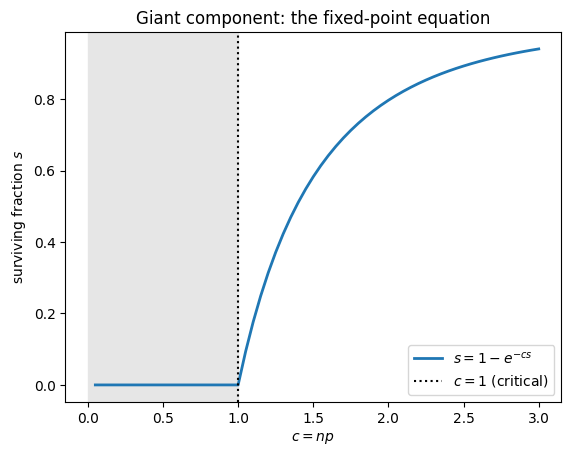

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components


def er_sizes(n, p, rng):
    '''Largest component size and number of components of G(n, p).

    Edges are sampled by drawing the binomial number of edges and then choosing
    their endpoints uniformly; for p = c/n the fraction of repeated pairs is
    O(1/n), which is negligible for the sizes we look at.
    '''
    m = rng.binomial(n * (n - 1) // 2, p)
    i = rng.integers(0, n, size=m)
    j = rng.integers(0, n, size=m)
    keep = i != j
    a = coo_matrix((np.ones(keep.sum()), (i[keep], j[keep])), shape=(n, n))
    ncomp, labels = connected_components(a, directed=False)
    return np.bincount(labels).max(), ncomp


def survival(c):
    '''Positive root of s = 1 - exp(-c s); zero for c <= 1 (bisection).'''
    if c <= 1:
        return 0.0
    lo, hi = 0.0, 1.0
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        if mid - (1 - np.exp(-c * mid)) < 0:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)


cs = np.linspace(0.05, 3.0, 60)
theory = np.array([survival(c) for c in cs])

plt.plot(cs, theory, lw=2, label=r"$s=1-e^{-cs}$")
plt.axvline(1, c="k", ls=":", label=r"$c=1$ (critical)")
plt.axvspan(0, 1, color="0.9", zorder=0)
plt.xlabel(r"$c=np$")
plt.ylabel("surviving fraction $s$")
plt.title("Giant component: the fixed-point equation")
plt.legend()
plt.show()

## 3. Why the threshold is $p = 1/n$ and not a constant

The expectation of the degree is $(n-1)p$, so the question "is the mean degree above or below
one?" is a question about the product $np$, not about $p$. Two consequences:

- **Scaling.** $p = c/n$ keeps the mean degree fixed while $n$ grows. Any constant $p$ gives a
  graph that is a single dense blob — every vertex has $\Theta(n)$ neighbours — and the notion of
  "component" loses its interest. The interesting regime lives at scale $1/n$.
- **Sharpness.** The transition is not spread over an interval of $p$ of constant length: at the
  scale $c = 1 + \lambda n^{-1/3}$ the largest component changes size, so the window has width
  $\Theta(n^{-2/3})$ in the number of edges, which is $\Theta(n^{-1/3})$ in $c$. On the $c$ axis
  the transition *looks* sharp for large $n$ and blunt for small $n$ — exactly the finite-size
  effect we see in the next plot.

The same rescaling appears once more in this page: connectivity happens at
$p = (\log n)/n$, again $1/n$ times a slowly growing factor.


    c    s(c)    n=300   n=1500   n=6000
 0.30   0.000    0.022    0.005    0.002
 0.50   0.000    0.025    0.009    0.003
 0.70   0.000    0.041    0.021    0.005
 0.85   0.000    0.062    0.028    0.011
 0.95   0.000    0.155    0.072    0.030
 1.00   0.000    0.176    0.077    0.052
 1.05   0.094    0.166    0.162    0.100
 1.15   0.249    0.299    0.256    0.250
 1.30   0.423    0.375    0.419    0.420
 1.50   0.583    0.541    0.564    0.584
 1.80   0.732    0.711    0.725    0.730
 2.20   0.844    0.829    0.837    0.842


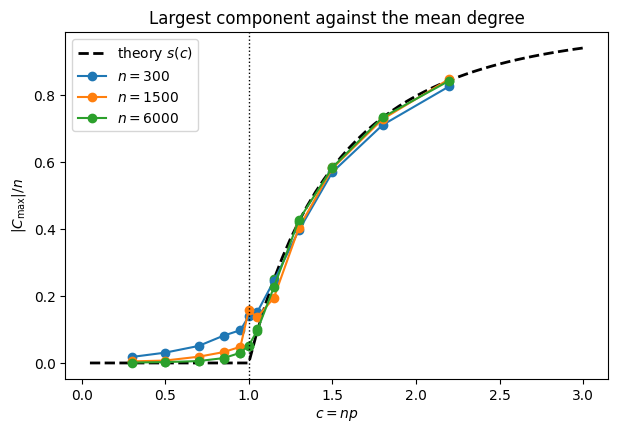

In [2]:
rng = np.random.default_rng(0)
grid = np.array([0.3, 0.5, 0.7, 0.85, 0.95, 1.0, 1.05, 1.15, 1.3, 1.5, 1.8, 2.2])
REPS = 8

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(cs, theory, "k--", lw=2, label="theory $s(c)$")

print(f"{'c':>5} {'s(c)':>7} " + " ".join(f"{'n=' + str(n):>8}" for n in (300, 1500, 6000)))
for c in grid:
    row = [np.mean([er_sizes(n, c / n, rng)[0] / n for _ in range(REPS)])
           for n in (300, 1500, 6000)]
    print(f"{c:5.2f} {survival(c):7.3f} " + " ".join(f"{v:8.3f}" for v in row))
    ax.plot([c], [row[-1]], "o", c="C2")

for n, colour in zip((300, 1500, 6000), ("C0", "C1", "C2")):
    mean = [np.mean([er_sizes(n, c / n, rng)[0] / n for _ in range(REPS)]) for c in grid]
    ax.plot(grid, mean, "o-", c=colour, label=f"$n={n}$")

ax.axvline(1, c="k", ls=":", lw=1)
ax.set_xlabel(r"$c=np$")
ax.set_ylabel(r"$|C_{\max}|/n$")
ax.set_title("Largest component against the mean degree")
ax.legend()
plt.show()

Small $n$ rounds the corner of the curve and pushes the apparent threshold to the right: for
$n = 300$ the giant component only clearly appears around $c \approx 1.5$, while the limiting curve
turns at $c = 1$. This is the finite-size window of the previous section, not a disagreement with
the theory. Note also that close to $c = 1$ eight repetitions are not enough: half of the runs have a
giant component and half do not, so the average jumps around. That is the bimodality of the
next plot, seen from the outside.

A sharper diagnostic than the mean is the **distribution** of $|C_{\max}|$ at a fixed $c$ near $1$.
Below the threshold it is small and concentrated; above it, a fraction $s$ of the runs produce a
giant component while the rest stay small, so the histogram is bimodal right at the transition.

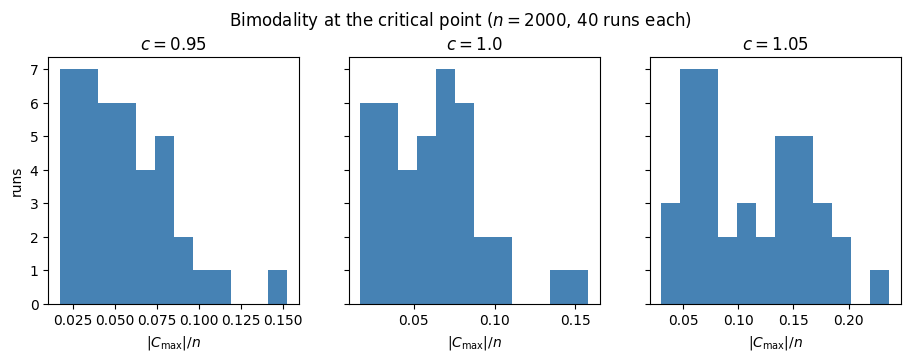

In [3]:
n = 2000
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, c in zip(axes, (0.95, 1.0, 1.05)):
    fracs = [er_sizes(n, c / n, rng)[0] / n for _ in range(40)]
    ax.hist(fracs, bins=12, color="steelblue")
    ax.set_title(f"$c={c}$")
    ax.set_xlabel(r"$|C_{\max}|/n$")
axes[0].set_ylabel("runs")
fig.suptitle("Bimodality at the critical point ($n=2000$, 40 runs each)", y=1.03)
plt.show()

## 4. The second threshold: connectivity

A graph can have a giant component and still be disconnected: one isolated vertex is enough. The
component of a fixed vertex has size $n$ only if the branching process stays alive *and* reaches
every one of the remaining $n-1$ vertices; the latter costs about $(\log n)$ generations, and the
resulting threshold is

$$
p = \frac{\log n}{n} .
$$

The reason the extra factor is logarithmic is the coupon-collector argument: the last isolated
vertex is found by a union bound over $n$ vertices, each isolated with probability
$(1-p)^{n-1} \approx e^{-np}$, and $n e^{-np} \to 0$ requires $np > \log n$. So the graph becomes
connected a constant factor *above* the point where the giant component appears.

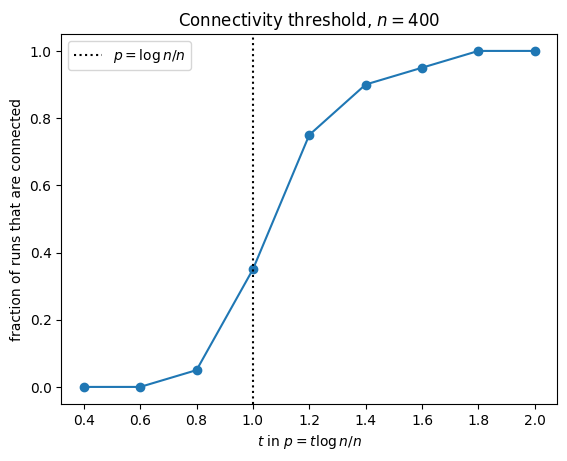

In [4]:
n = 400
ts = np.linspace(0.4, 2.0, 9)
connected = [np.mean([er_sizes(n, t * np.log(n) / n, rng)[1] == 1 for _ in range(20)]) for t in ts]

plt.plot(ts, connected, "o-")
plt.axvline(1, c="k", ls=":", label=r"$p=\log n/n$")
plt.xlabel(r"$t$ in $p = t\log n/n$")
plt.ylabel("fraction of runs that are connected")
plt.title(f"Connectivity threshold, $n={n}$")
plt.legend()
plt.show()

## 5. Small world: one paragraph

Erdős–Rényi graphs have short paths (diameter $\Theta(\log n)$) but almost no triangles. Real
networks — social, biological, citation — have both. Watts and Strogatz start from a ring where
each vertex is joined to its $k$ nearest neighbours, so clustering is high and paths are long, and
then **rewire** each edge with probability $\beta$ to a uniformly random vertex. A tiny $\beta$
destroys the long paths (a few shortcuts are enough) while leaving most local triangles intact:
the small-world regime. The model is here only as a bridge — clustering coefficients, path lengths
and the degree distributions of real networks belong to a graph-mining course.

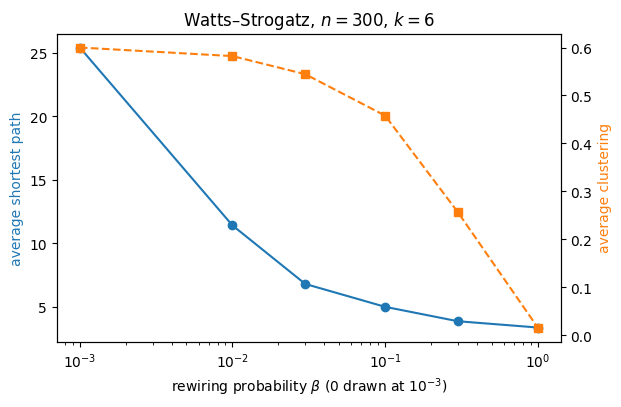

In [5]:
betas = [0.0, 0.01, 0.03, 0.1, 0.3, 1.0]
paths, clustering = [], []
for b in betas:
    g = nx.watts_strogatz_graph(300, 6, b, seed=1)
    paths.append(nx.average_shortest_path_length(g))
    clustering.append(nx.average_clustering(g))

fig, ax1 = plt.subplots(figsize=(6.5, 4))
ax1.semilogx(np.maximum(betas, 1e-3), paths, "o-", c="C0")
ax1.set_xlabel(r"rewiring probability $\beta$ (0 drawn at $10^{-3}$)")
ax1.set_ylabel("average shortest path", c="C0")

ax2 = ax1.twinx()
ax2.semilogx(np.maximum(betas, 1e-3), clustering, "s--", c="C1")
ax2.set_ylabel("average clustering", c="C1")
ax1.set_title(r"Watts–Strogatz, $n=300$, $k=6$")
plt.show()

## 6. What to remember

1. The component of a vertex is a branching process with mean offspring $c = np$; the giant
   component exists iff $c > 1$, that is iff $p > 1/n$.
2. Its asymptotic size is the survival probability $s$, the positive root of $s = 1 - e^{-cs}$,
   which behaves like $2(c-1)/c^2$ near the threshold.
3. Two different thresholds live at the same scale $1/n$: the giant component at $c = 1$ and
   connectivity at $p = \log n / n$.
4. The tree-like approximation behind the branching process is what fails for the size, not for
   the threshold: loops are rare exactly when $p = c/n$.

The next page uses a graph as a state space rather than as a random object: a random walk on a
fixed graph, its stationary distribution, and PageRank.


## Exercises

1. Model the component of a vertex as a branching process with Poisson offspring of mean $c=np$.
   Show that the survival probability is zero for $c\le1$ and solve $1-s=e^{-cs}$ for $c>1$.
2. Simulate $G(n,p)$ for $n=10^4$ with $p$ around $1/n$, plot the size of the largest component
   against $np$, and locate the transition.
3. Explain why the threshold is $p=1/n$ and not a constant: rescale $p$ by $n$ and say which
   quantity stays fixed.
4. Show that the expected number of triangles is $\binom{n}{3}p^3$ and that it tends to a constant
   when $p = c/n$. Explain why the branching-process approximation of the component is *exact* in
   this regime (hint: count cycles).
5. Let $q$ be the extinction probability. Prove that $q=1$ is always a root of $q = e^{-c(1-q)}$,
   and that the equation has a second root in $[0,1)$ if and only if $c>1$, by looking at the
   derivative of $f(q) = e^{-c(1-q)} - q$ at $q=1$.
6. Use the coupon-collector argument to show that $p = \tfrac{1+\varepsilon}{n}\log n$ makes the
   probability of an isolated vertex tend to zero, and that $p = \tfrac{1-\varepsilon}{n}\log n$
   leaves $\Theta(n^{\varepsilon})$ isolated vertices on average.
7. In the Watts–Strogatz experiment above, explain why the clustering coefficient barely changes
   for $\beta \le 0.03$ while the average path length already collapses. Which of the two is a
   *local* quantity?


## Sources

- Blum, Hopcroft, Kannan, *Foundations of Data Science*, Ch. 7–8 (branching processes and the
  giant component).
- Durrett, *Random Graph Dynamics*, Ch. 1–2 (the critical window and the $n^{-1/3}$ scale).
- Watts, D. and Strogatz, S., "Collective dynamics of 'small-world' networks", *Nature* 393, 1998.
- Bollobás, *Random Graphs*, Ch. 5–7 (connectivity and the $(\log n)/n$ threshold).
